In [145]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test
from scipy.stats import linregress

# ========= 输出路径 =========
OUT_DIR = r"C:\greenland\1995bu\fig4"
os.makedirs(OUT_DIR, exist_ok=True)

# ========= 文件路径 =========
files = {
    "t2m":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "strd": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "ssrd": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "rf":   r"C:\greenland\sf_tp_rf.nc",
    "tcc":  r"C:\Users\greenlandProject\ERA5LAND\greenland_tcc_full.nc",
}

# ========= 函数 =========
def calc_summer_mean(ds, varname):
    """提取夏季 (JJA) 年度均值"""
    time_name = "valid_time" if "valid_time" in ds.coords else "time"
    da = ds[varname]
    da = da.assign_coords(time=ds[time_name])
    da = da.swap_dims({time_name: "time"})
    da["month"] = da["time"].dt.month
    da["year"] = da["time"].dt.year
    da_summer = da.where(da["month"].isin([6,7,8]), drop=True)
    summer_mean = da_summer.groupby("year").mean(dim="time", skipna=True)
    return summer_mean

def mk_trend_per_decade(y):
    y = np.array(y)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_grid_mean_trend(da):
    """计算每格点均值 + MK趋势"""
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    lats = da[lat_name].values
    lons = da[lon_name].values
    
    mean_map = da.mean(dim="year", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["year"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )
    
    LAT, LON = np.meshgrid(lats, lons, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

def compute_sliding_trend(years, series):
    n = len(years)
    trend_matrix = np.full((n, n), np.nan)
    for i in range(n - 1):
        for j in range(i + 1, n):
            y = series[i:j+1]
            if np.isnan(y).sum() < len(y) - 2:
                slope, _, _, _, _ = linregress(np.arange(len(y)), y)
                trend_matrix[i, j] = slope
    df = pd.DataFrame(trend_matrix, index=years, columns=years)
    return df

# ========= 主循环 =========
for var, path in files.items():
    print(f"\n===== Processing {var} =====")
    
    # ✅ 检查CSV是否已存在（只检查一个，因为两个总是同时生成）
    out_meantrend = os.path.join(OUT_DIR, f"Greenland_{var}_MeanTrend.csv")
    out_slide = os.path.join(OUT_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    if os.path.exists(out_meantrend):
        print(f"⏭️  {var} 的CSV已存在，跳过")
        continue
    
    # 打开数据集
    ds = xr.open_dataset(path)
    if var not in ds.data_vars:
        print(f"⚠️  Variable {var} not found in {path}")
        ds.close()
        continue
    
    da = calc_summer_mean(ds, var)
    ds.close()
    print(f"✅ Summer mean shape: {da.shape}")
    
    # ---- 均值 + MK 趋势 ----
    print("⏳ Calculating MK trend per grid...")
    df_mt = compute_grid_mean_trend(da)
    df_mt.to_csv(out_meantrend, index=False)
    print(f"💾 Saved: {out_meantrend}")
    
    # ---- 滑动趋势 ----
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    area_mean = da.mean(dim=[lat_name, lon_name], skipna=True).values
    years = da.year.values
    
    print("⏳ Calculating sliding trends...")
    df_slide = compute_sliding_trend(years, area_mean)
    df_slide.to_csv(out_slide, index=True)
    print(f"💾 Saved: {out_slide}")

print("\n✅ 全部5个变量（t2m, strd, ssrd, rf, tcc）处理完成！结果保存在 C:\\greenland\\1995bu\\fig4")


===== Processing t2m =====
⏭️  t2m 的CSV已存在，跳过

===== Processing strd =====
✅ Summer mean shape: (75, 239, 612)
⏳ Calculating MK trend per grid...
💾 Saved: C:\greenland\1995bu\fig4\Greenland_strd_MeanTrend.csv
⏳ Calculating sliding trends...
💾 Saved: C:\greenland\1995bu\fig4\Greenland_strd_SlidingTrend.csv

===== Processing ssrd =====
⏭️  ssrd 的CSV已存在，跳过

===== Processing rf =====
⏭️  rf 的CSV已存在，跳过

===== Processing tcc =====
⏭️  tcc 的CSV已存在，跳过

✅ 全部5个变量（t2m, strd, ssrd, rf, tcc）处理完成！结果保存在 C:\greenland\1995bu\fig4


In [16]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test

# ========= 文件路径与输出路径 =========
NC_PATH  = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_PATH = r"C:\greenland\1995bu\fig4\Greenland_alb_MeanTrend.csv"

# ========= 函数定义 =========
def mk_trend_per_decade(y):
    """对每个像元时间序列做 Mann-Kendall 趋势检验，返回每十年变化率"""
    y = np.array(y, dtype=float)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_mean_trend(da):
    """计算均值和MK趋势"""
    lat = da["lat"].values
    lon = da["lon"].values

    mean_map = da.mean(dim="time", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["time"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )

    LAT, LON = np.meshgrid(lat, lon, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

# ========= 主程序 =========
print("===== Processing Greenland albedo =====")

ds = xr.open_dataset(NC_PATH)
da = ds["albedo"]

print(f"✅ 数据读取完成: {da.shape}, dims={list(da.dims)}")

df = compute_mean_trend(da)

# ========= 输出 =========
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
df.to_csv(OUT_PATH, index=False)
print(f"💾 已保存: {OUT_PATH}")
print("\n✅ 完成！文件内容包含 lat, lon, mean, trend_per_decade 四列。")


===== Processing Greenland albedo =====
✅ 数据读取完成: (75, 237, 612), dims=['time', 'lat', 'lon']
💾 已保存: C:\greenland\1995bu\fig4\Greenland_alb_MeanTrend.csv

✅ 完成！文件内容包含 lat, lon, mean, trend_per_decade 四列。


In [1]:
import numpy as np
import pandas as pd
import xarray as xr
from sklearn.linear_model import LinearRegression

# ===== 路径 (Path - 请根据你的实际路径修改) =====
nc_path = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
output_path = r"C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv"

# ===== 1. 读取并计算格陵兰平均 Albedo =====
try:
    ds = xr.open_dataset(nc_path)
except FileNotFoundError:
    print(f"ERROR: File not found at {nc_path}. Please check the path.")
    exit()

# 自动识别包含"albedo"的变量名
varname = [v for v in ds.data_vars if "albedo" in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim=("lat", "lon"), skipna=True)

# ===== 2. 识别时间维度 =====
time_values = albedo_mean["time"].values
if np.issubdtype(time_values.dtype, np.number):
    years = np.array(time_values).astype(int)
else:
    # 提取年份
    years = pd.to_datetime(time_values).year
vals = albedo_mean.values
print(f"✅ Data range: {years.min()}–{years.max()} ({len(years)} years)")

# ===== 3. 计算滑动趋势矩阵（右上角结构） =====
n = len(years)
# 初始化一个全为 NaN 的矩阵
trend_matrix = np.full((n, n), np.nan) 

# 外层循环: Start Year index (对应矩阵的行 i)
for i in range(n): 
    # 内层循环: End Year index (对应矩阵的列 j)
    # 确保时段长度至少为 3 年 (j - i + 1 >= 3)，所以 j >= i + 2
    for j in range(i + 2, n): 
        
        # 截取从 i 到 j (包含 j) 的年份和数据
        x = np.array(years[i:j+1]).reshape(-1, 1) # 时间变量 (自变量)
        y = vals[i:j+1]                           # Albedo 值 (因变量)
        
        # 确保有足够多的有限值来进行线性回归 (至少2个点，但我们要求至少3年)
        if np.isfinite(y).sum() >= 2: 
            model = LinearRegression().fit(x, y)
            # 将趋势值存入矩阵的 [Start Year Index, End Year Index]，即右上角
            trend_matrix[i, j] = model.coef_[0] 
        else:
            # 如果数据点不足，保持为 NaN
            trend_matrix[i, j] = np.nan

# ===== 4. 创建 DataFrame 并保存为 CSV =====
# 创建 DataFrame，行索引和列索引都是年份
df = pd.DataFrame(trend_matrix, index=years, columns=years)

# 保存为 CSV 文件
df.to_csv(output_path, index=True, na_rep='')
print(f"✅ CSV file saved to: {output_path}")

# 显示前几行预览
print("\n前5行5列预览:")
print(df.iloc[:5, :5])

ds.close() # 关闭 xarray 数据集


✅ Data range: 1950–2024 (75 years)
✅ CSV file saved to: C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv

前5行5列预览:
      1950  1951      1952      1953      1954
1950   NaN   NaN  0.004835  0.002649  0.002529
1951   NaN   NaN       NaN -0.001646  0.000322
1952   NaN   NaN       NaN       NaN  0.002311
1953   NaN   NaN       NaN       NaN       NaN
1954   NaN   NaN       NaN       NaN       NaN


In [ ]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test

# ========= 文件路径与输出路径 =========
NC_PATH  = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_PATH = r"C:\greenland\1995bu\fig4\Greenland_alb_MeanTrend.csv"

# ========= 函数定义 =========
def mk_trend_per_decade(y):
    """对每个像元时间序列做 Mann-Kendall 趋势检验，返回每十年变化率"""
    y = np.array(y, dtype=float)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_mean_trend(da):
    """计算均值和MK趋势"""
    lat = da["lat"].values
    lon = da["lon"].values

    mean_map = da.mean(dim="time", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["time"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )

    LAT, LON = np.meshgrid(lat, lon, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

# ========= 主程序 =========
print("===== Processing Greenland albedo =====")

ds = xr.open_dataset(NC_PATH)
da = ds["albedo"]

print(f"✅ 数据读取完成: {da.shape}, dims={list(da.dims)}")

df = compute_mean_trend(da)

# ========= 输出 =========
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
df.to_csv(OUT_PATH, index=False)
print(f"💾 已保存: {OUT_PATH}")
print("\n✅ 完成！文件内容包含 lat, lon, mean, trend_per_decade 四列。")



────────────────────────────────────────────────────────────────────────────────
【文件路径】
────────────────────────────────────────────────────────────────────────────────
C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc

────────────────────────────────────────────────────────────────────────────────
【基本打开（decode_cf=False / True）】
────────────────────────────────────────────────────────────────────────────────

────────────────────────────────────────────────────────────────────────────────
【数据集基本信息（decode_cf=False）】
────────────────────────────────────────────────────────────────────────────────
  data_vars: ['albedo']
  coords:    ['lat', 'lon', 'time']
  dims:      {'lat': 237, 'lon': 612, 'time': 75}
  dataset attrs (0):
    (no attrs)

────────────────────────────────────────────────────────────────────────────────
【数据集基本信息（decode_cf=True）】
────────────────────────────────────────────────────────────────────────────────
  data_vars: ['albedo']
  coords:    ['lat', 'lon', 'tim

C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2128983320.py:148: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  dims:      {dict(ds_raw.dims)}")
C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2128983320.py:155: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  dims:      {dict(ds_cf.dims)}")


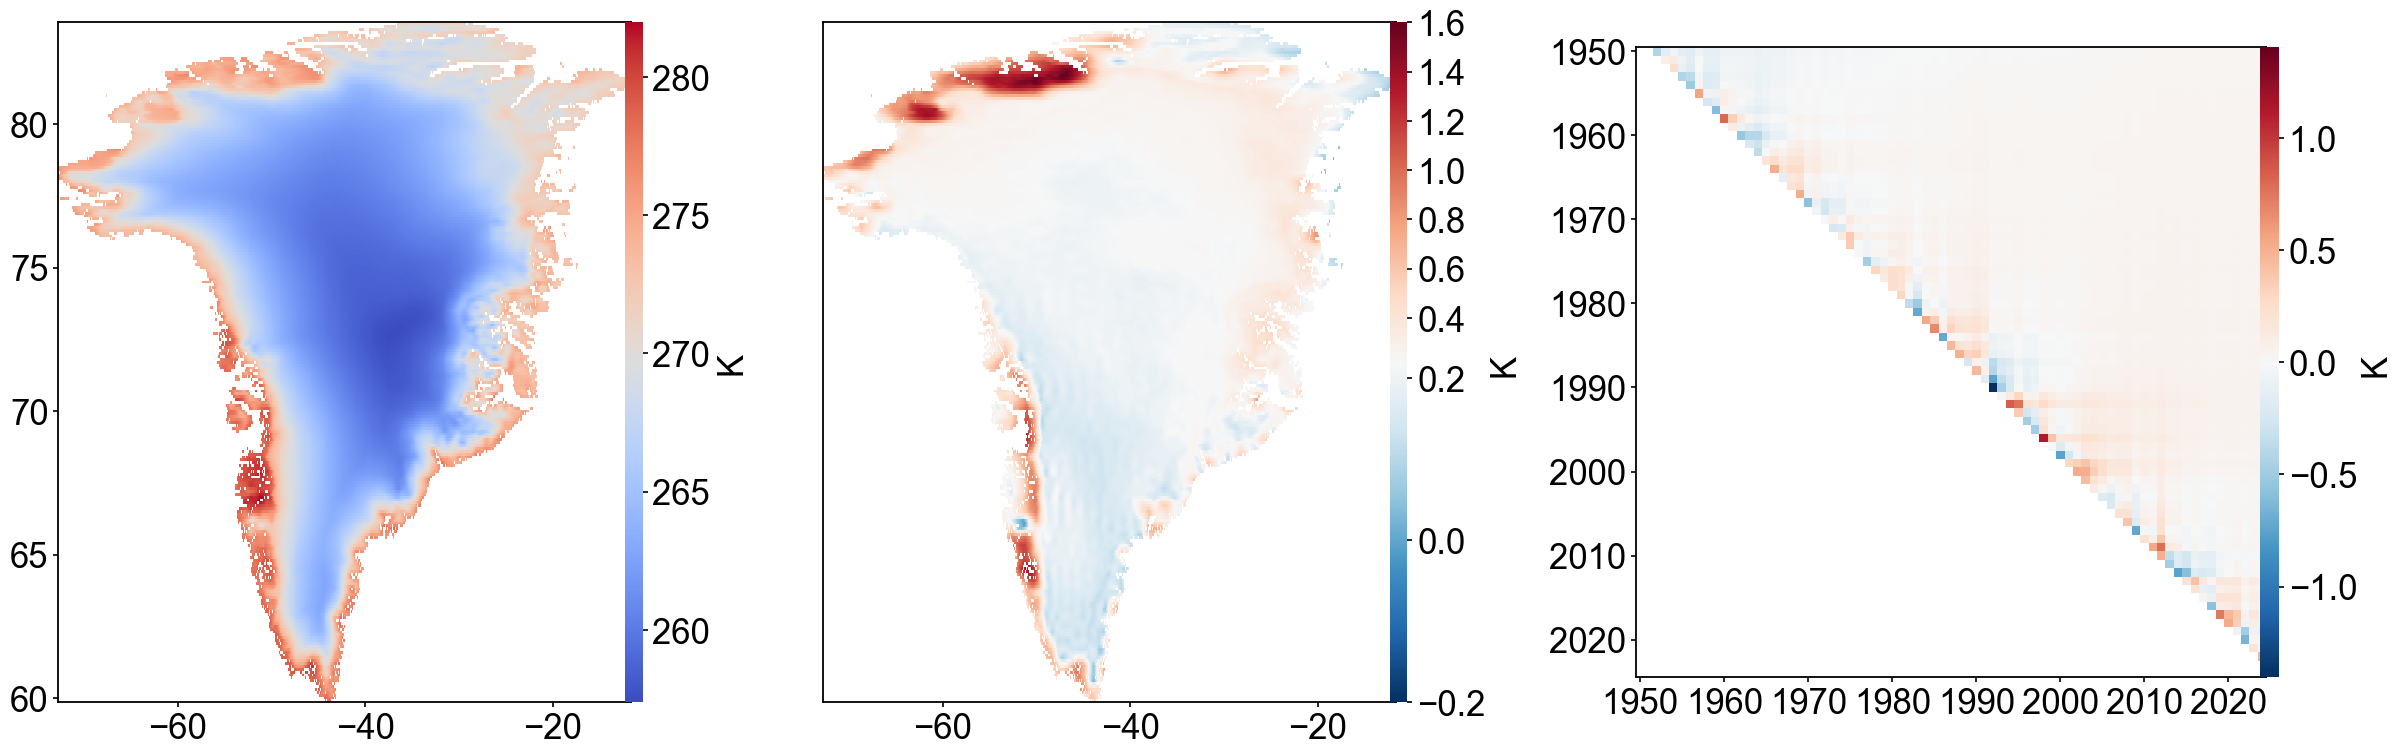

In [5]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 =====
meantrend_csv = r"C:\greenland\1995bu\fig4\Greenland_t2m_MeanTrend.csv"
sliding_csv   = r"C:\greenland\1995bu\fig4\Greenland_t2m_SlidingTrend.csv"

# ===== 参数区 =====
FONT_SIZE      = 25
CBAR_WIDTH     = "3%"       # 统一colorbar宽度
CBAR_PAD       = 0.02       # colorbar与子图间距
WSPACE_12      = 0.08       # 图1和图2之间的间距
WSPACE_23      = 0.1       # 图2和图3之间的间距
TOP_ALIGN      = 0.95       # 三个子图顶部对齐高度

UNIT_MEAN      = "K"
UNIT_TREND     = "K "
UNIT_SLIDE     = "K "

# 图2的colorbar范围
TREND_VMIN     = -0.2
TREND_VCENTER  = 0.22
TREND_VMAX     = 1.6

# ===== 读数据 =====
df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])

# ===== pivot重构格网 =====
mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
lats, lons = mean_grid.index.values, mean_grid.columns.values

# ===== 滑动趋势 =====
slide = pd.read_csv(sliding_csv, index_col=0)
years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
vals = slide.to_numpy(dtype=float)
mask = np.tril(np.ones_like(vals, dtype=bool), -1)
vals_masked = np.ma.array(vals, mask=mask)

# ===== 绘图风格 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

# ===== 图形布局 =====
fig = plt.figure(figsize=(24, 8))

# 手动计算每个子图的位置
left_margin = 0.05
right_margin = 0.97
total_width = right_margin - left_margin

# 三个子图的相对宽度比例
w1_ratio = 1.0
w2_ratio = 1.0
w3_ratio = 1.1
total_ratio = w1_ratio + w2_ratio + w3_ratio

# 计算可用于子图的总宽度（减去间距）
total_gap = WSPACE_12 + WSPACE_23
available_width = total_width - total_gap

# 计算每个子图的实际宽度
w1 = available_width * (w1_ratio / total_ratio)
w2 = available_width * (w2_ratio / total_ratio)
w3 = available_width * (w3_ratio / total_ratio)

# 计算每个子图的left位置
left1 = left_margin
left2 = left1 + w1 + WSPACE_12
left3 = left2 + w2 + WSPACE_23

# 创建子图
ax0 = fig.add_axes([left1, 0.1, w1, TOP_ALIGN - 0.1])
ax1 = fig.add_axes([left2, 0.1, w2, TOP_ALIGN - 0.1], sharey=ax0)
ax2 = fig.add_axes([left3, 0.1, w3, TOP_ALIGN - 0.1])

# === (1) 夏季均值 ===
im0 = ax0.pcolormesh(lons, lats, mean_grid.values, cmap="coolwarm", shading="auto")
cb0_ax = inset_axes(ax0, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax0.transAxes, borderpad=0)
cb0 = fig.colorbar(im0, cax=cb0_ax)
cb0.set_label(UNIT_MEAN, fontsize=FONT_SIZE)
cb0.outline.set_visible(False)

# === (2) MK趋势 ===
norm = TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX)
im1 = ax1.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r", norm=norm, shading="auto")

# colorbar紧贴ax1右侧
cb1_ax = inset_axes(ax1, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax1.transAxes, borderpad=0)
cb1 = fig.colorbar(im1, cax=cb1_ax)
cb1.set_label(UNIT_TREND, fontsize=FONT_SIZE)
cb1.outline.set_visible(False)

# 隐藏图2的y轴，只保留图1的纬度
ax1.tick_params(left=False, labelleft=False)

# === (3) 滑动趋势热力图 ===
vmax_slide = np.nanmax(np.abs(vals_masked))
norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
im2 = ax2.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r", norm=norm_slide, shading="auto")
ax2.invert_yaxis()

cb2_ax = inset_axes(ax2, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax2.transAxes, borderpad=0)
cb2 = fig.colorbar(im2, cax=cb2_ax)
cb2.set_label(UNIT_SLIDE, fontsize=FONT_SIZE)
cb2.outline.set_visible(False)

# === 样式 ===
for ax in [ax0, ax1, ax2]:
    ax.tick_params(labelsize=FONT_SIZE)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")

ax2.set_xticks(np.arange(1950, 2030, 10))
ax2.set_yticks(np.arange(1950, 2030, 10))
ax2.set_aspect('equal')

plt.show()

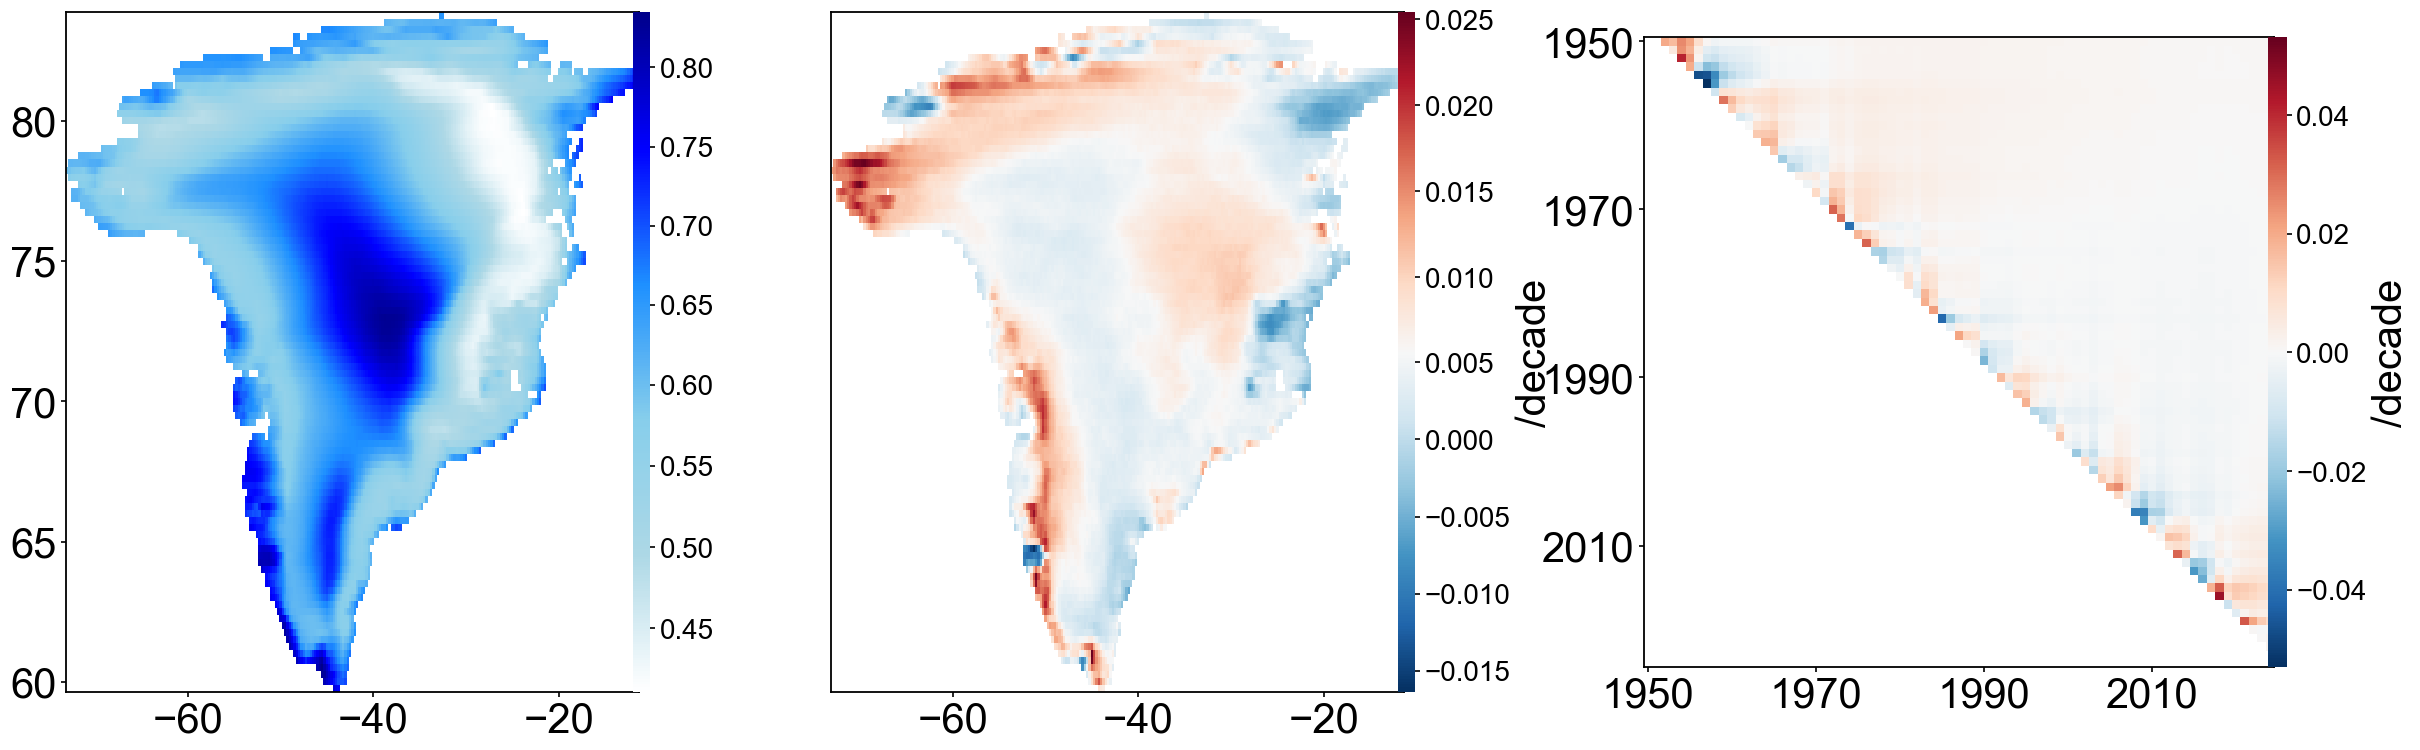

In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 =====
meantrend_csv = r"C:\greenland\1995bu\fig4\Greenland_tcc_MeanTrend.csv"
sliding_csv   = r"C:\greenland\1995bu\fig4\Greenland_tcc_SlidingTrend.csv"

# ===== 参数区 =====
FONT_SIZE      = 30
CBAR_WIDTH     = "3%"
CBAR_PAD       = 0.02
WSPACE_12      = 0.08
WSPACE_23      = 0.1
TOP_ALIGN      = 0.95

UNIT_MEAN      = ""
UNIT_TREND     = " "
UNIT_SLIDE     = " "

# ===== 读取数据 =====
df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])

# ===== pivot重构格网 =====
mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
lats, lons = mean_grid.index.values, mean_grid.columns.values

# ===== 滑动趋势 =====
slide = pd.read_csv(sliding_csv, index_col=0)
years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
vals = slide.to_numpy(dtype=float)
mask = np.tril(np.ones_like(vals, dtype=bool), -1)
vals_masked = np.ma.array(vals, mask=mask)

# ===== 绘图风格 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

# ===== 图形布局 =====
fig = plt.figure(figsize=(24, 8))
left_margin, right_margin = 0.05, 0.97
total_width = right_margin - left_margin

w1_ratio, w2_ratio, w3_ratio = 1.0, 1.0, 1.1
total_ratio = w1_ratio + w2_ratio + w3_ratio
total_gap = WSPACE_12 + WSPACE_23
available_width = total_width - total_gap
w1 = available_width * (w1_ratio / total_ratio)
w2 = available_width * (w2_ratio / total_ratio)
w3 = available_width * (w3_ratio / total_ratio)

left1 = left_margin
left2 = left1 + w1 + WSPACE_12
left3 = left2 + w2 + WSPACE_23

ax0 = fig.add_axes([left1, 0.1, w1, TOP_ALIGN - 0.1])
ax1 = fig.add_axes([left2, 0.1, w2, TOP_ALIGN - 0.1], sharey=ax0)
ax2 = fig.add_axes([left3, 0.1, w3, TOP_ALIGN - 0.1])

# === (1) 均值 - 云量配色方案 ===
# 创建自定义colormap：低值浅色(少云)，高值深色(多云)
colors_cloud = ['white', 'lightblue', 'skyblue', 'dodgerblue', 'blue', 'darkblue']
cmap_cloud = LinearSegmentedColormap.from_list('cloud', colors_cloud)

# 设置颜色映射范围，您可以手动调整vmin, vmax, vcenter来控制中间值
vmin_mean = np.nanmin(mean_grid.values)
vmax_mean = np.nanmax(mean_grid.values)
vcenter_mean = 0.62  # 中间值，可以手动设置如: vcenter_mean = 50

# 使用TwoSlopeNorm来精确控制中间值的颜色映射
norm_mean = TwoSlopeNorm(vmin=vmin_mean, vcenter=vcenter_mean, vmax=vmax_mean)

im0 = ax0.pcolormesh(lons, lats, mean_grid.values, 
                     cmap=cmap_cloud, 
                     norm=norm_mean,
                     shading="auto")

cb0_ax = inset_axes(ax0, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1),
                    bbox_transform=ax0.transAxes, borderpad=0)
cb0 = fig.colorbar(im0, cax=cb0_ax)
cb0.set_label(UNIT_MEAN, fontsize=FONT_SIZE)
cb0.outline.set_visible(False)

# === (2) 趋势 ===
vmin = np.nanmin(trend_grid.values)
vmax = np.nanmax(trend_grid.values)
vcenter = np.nanmedian(trend_grid.values)  # ← 取中位数为中心
norm = TwoSlopeNorm(vmin=vmin, vcenter=vcenter, vmax=vmax)
im1 = ax1.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r", norm=norm, shading="auto")

cb1_ax = inset_axes(ax1, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1),
                    bbox_transform=ax1.transAxes, borderpad=0)
cb1 = fig.colorbar(im1, cax=cb1_ax)
cb1.set_label(UNIT_TREND, fontsize=FONT_SIZE)
cb1.outline.set_visible(False)

ax1.tick_params(left=False, labelleft=False)

# === (3) 滑动趋势 ===
vmax_slide = np.nanmax(np.abs(vals_masked))
norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
im2 = ax2.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r", norm=norm_slide, shading="auto")
ax2.invert_yaxis()

cb2_ax = inset_axes(ax2, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1),
                    bbox_transform=ax2.transAxes, borderpad=0)
cb2 = fig.colorbar(im2, cax=cb2_ax)
cb2.set_label(UNIT_SLIDE, fontsize=FONT_SIZE)
cb2.outline.set_visible(False)

# === 样式 ===
for ax in [ax0, ax1, ax2]:
    ax.tick_params(labelsize=FONT_SIZE)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")

ax2.set_xticks(np.arange(1950, 2030, 20))
ax2.set_yticks(np.arange(1950, 2030, 20))
ax2.set_aspect('equal')

plt.show()

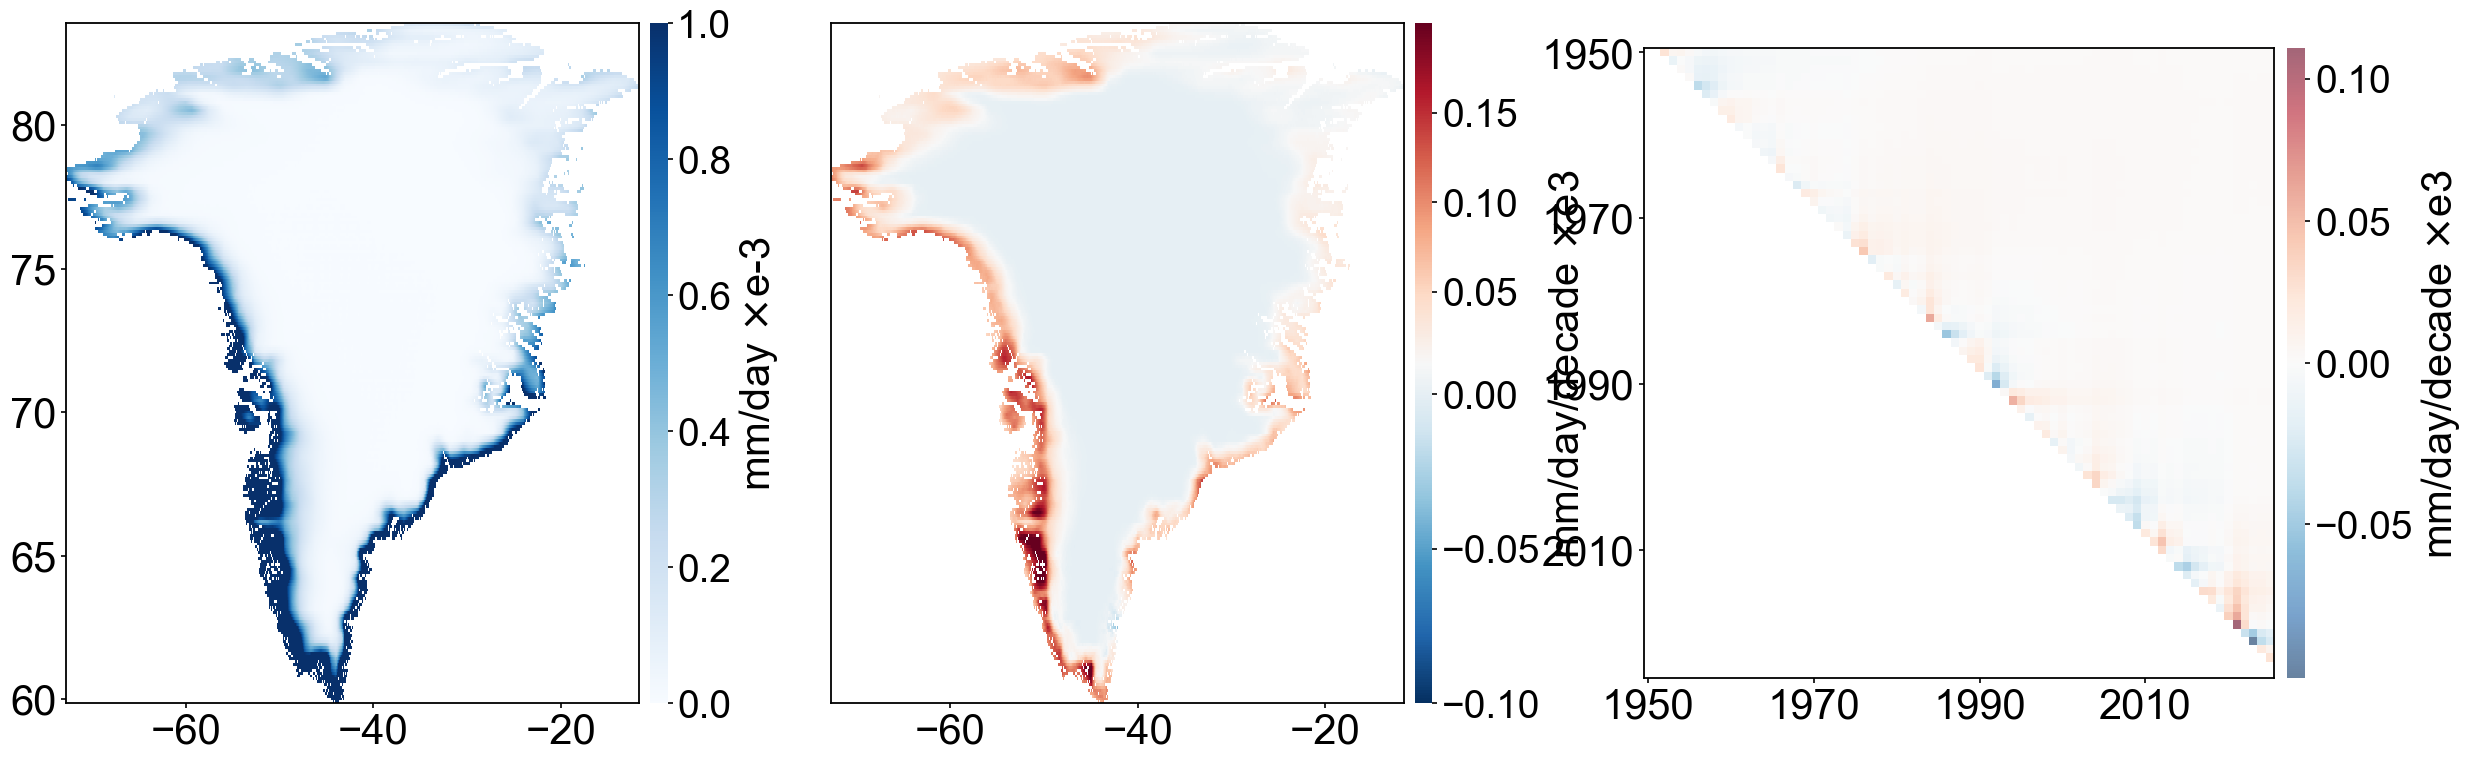

In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 =====
meantrend_csv = r"C:\greenland\1995bu\fig4\Greenland_rf_MeanTrend.csv"
sliding_csv   = r"C:\greenland\1995bu\fig4\Greenland_rf_SlidingTrend.csv"

# ===== 参数区 =====
FONT_SIZE      = 30
CBAR_WIDTH     = "3%"
CBAR_PAD       = 0.05  # 增加colorbar与图的间距，避免遮盖
WSPACE_12      = 0.08
WSPACE_23      = 0.1
TOP_ALIGN      = 0.95

UNIT_MEAN      = r"mm/day $\times$e-3"  # 修改单位
UNIT_TREND     = r"mm/day  $\times$e3"  # 修改单位符号
UNIT_SLIDE     = r"mm/day  $\times$e3"  # 修改单位符号

# ===== 图2趋势中心值参数 =====
TREND_CENTER   = 0.01  # 白色分界线位置

# ===== 读数据 =====
df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])

# ===== pivot重构格网 =====
mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
lats, lons = mean_grid.index.values, mean_grid.columns.values

# ===== 缩放（使用全部数据）=====
mean_scaled  = mean_grid.values * 1e3         # 转换为 ×10⁻³ mm/day
trend_scaled = trend_grid.values * 1e3        # 转换为 ×10³ mm/day 

# ===== 设置色带参数 =====
# 图1: 降雨量均值 - 固定范围0到1
MEAN_VMIN = 0.0
MEAN_VMAX = 1.0

# 图2: 趋势 - 固定范围-0.1到0.2
trend_vmin = -0.1
trend_vmax = 0.2

# ===== 滑动趋势 =====
slide = pd.read_csv(sliding_csv, index_col=0)
years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
vals = slide.to_numpy(dtype=float) * 1e3   # 同样 ×10³
mask = np.tril(np.ones_like(vals, dtype=bool), -1)
vals_masked = np.ma.array(vals, mask=mask)

# 图3: 滑动趋势 - 使用全部数据范围
slide_vmin = np.nanmin(vals_masked[~mask])
slide_vmax = np.nanmax(vals_masked[~mask])

# ===== 绘图风格 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

# ===== 布局 =====
fig = plt.figure(figsize=(24, 8))
left_margin, right_margin = 0.05, 0.97
total_width = right_margin - left_margin
w1_ratio, w2_ratio, w3_ratio = 1.0, 1.0, 1.1
total_ratio = w1_ratio + w2_ratio + w3_ratio
total_gap = WSPACE_12 + WSPACE_23
available_width = total_width - total_gap
w1 = available_width * (w1_ratio / total_ratio)
w2 = available_width * (w2_ratio / total_ratio)
w3 = available_width * (w3_ratio / total_ratio)
left1 = left_margin
left2 = left1 + w1 + WSPACE_12
left3 = left2 + w2 + WSPACE_23

# ===== 子图 =====
ax0 = fig.add_axes([left1, 0.1, w1, TOP_ALIGN - 0.1])
ax1 = fig.add_axes([left2, 0.1, w2, TOP_ALIGN - 0.1], sharey=ax0)
ax2 = fig.add_axes([left3, 0.1, w3, TOP_ALIGN - 0.1])

# === (1) Mean 降雨量 - 固定刻度0到1 ===
norm_mean = Normalize(vmin=MEAN_VMIN, vmax=MEAN_VMAX)
im0 = ax0.pcolormesh(lons, lats, mean_scaled, cmap="Blues", norm=norm_mean, shading="auto")
cb0_ax = inset_axes(ax0, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax0.transAxes, borderpad=0)
cb0 = fig.colorbar(im0, cax=cb0_ax, ticks=np.arange(0, 1.2, 0.2))
cb0.set_label(f"{UNIT_MEAN}", fontsize=FONT_SIZE)
cb0.outline.set_visible(False)
cb0.ax.tick_params(labelsize=FONT_SIZE-2)

# === (2) 趋势 - 固定刻度-0.1到0.2 ===
norm_trend = TwoSlopeNorm(vmin=trend_vmin, vcenter=TREND_CENTER, vmax=trend_vmax)
im1 = ax1.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r", norm=norm_trend, shading="auto")
cb1_ax = inset_axes(ax1, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax1.transAxes, borderpad=0)
cb1 = fig.colorbar(im1, cax=cb1_ax, ticks=np.arange(-0.1, 0.25, 0.05))
cb1.set_label(f"{UNIT_TREND}", fontsize=FONT_SIZE)
cb1.outline.set_visible(False)
cb1.ax.tick_params(labelsize=FONT_SIZE-2)
ax1.tick_params(left=False, labelleft=False)

# === (3) 滑动趋势 - 淡化颜色 ===
import matplotlib.colors as mcolors
cmap_slide = plt.cm.RdBu_r
colors_slide = cmap_slide(np.linspace(0, 1, 256))
colors_slide[:, -1] = 0.6  # 设置alpha为0.6，淡化颜色
cmap_slide_light = mcolors.ListedColormap(colors_slide)

norm_slide = TwoSlopeNorm(vmin=slide_vmin, vcenter=0, vmax=slide_vmax)
im2 = ax2.pcolormesh(years, slide_years, vals_masked, cmap=cmap_slide_light, norm=norm_slide, shading="auto")
ax2.invert_yaxis()
cb2_ax = inset_axes(ax2, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax2.transAxes, borderpad=0)
cb2 = fig.colorbar(im2, cax=cb2_ax)
cb2.set_label(f"{UNIT_SLIDE}", fontsize=FONT_SIZE)
cb2.outline.set_visible(False)
cb2.ax.tick_params(labelsize=FONT_SIZE-2)

# ===== 样式 =====
for ax in [ax0, ax1, ax2]:
    ax.tick_params(labelsize=FONT_SIZE)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")

ax2.set_xticks(np.arange(1950, 2030, 20))
ax2.set_yticks(np.arange(1950, 2030, 20))
ax2.set_aspect('equal')

plt.show()

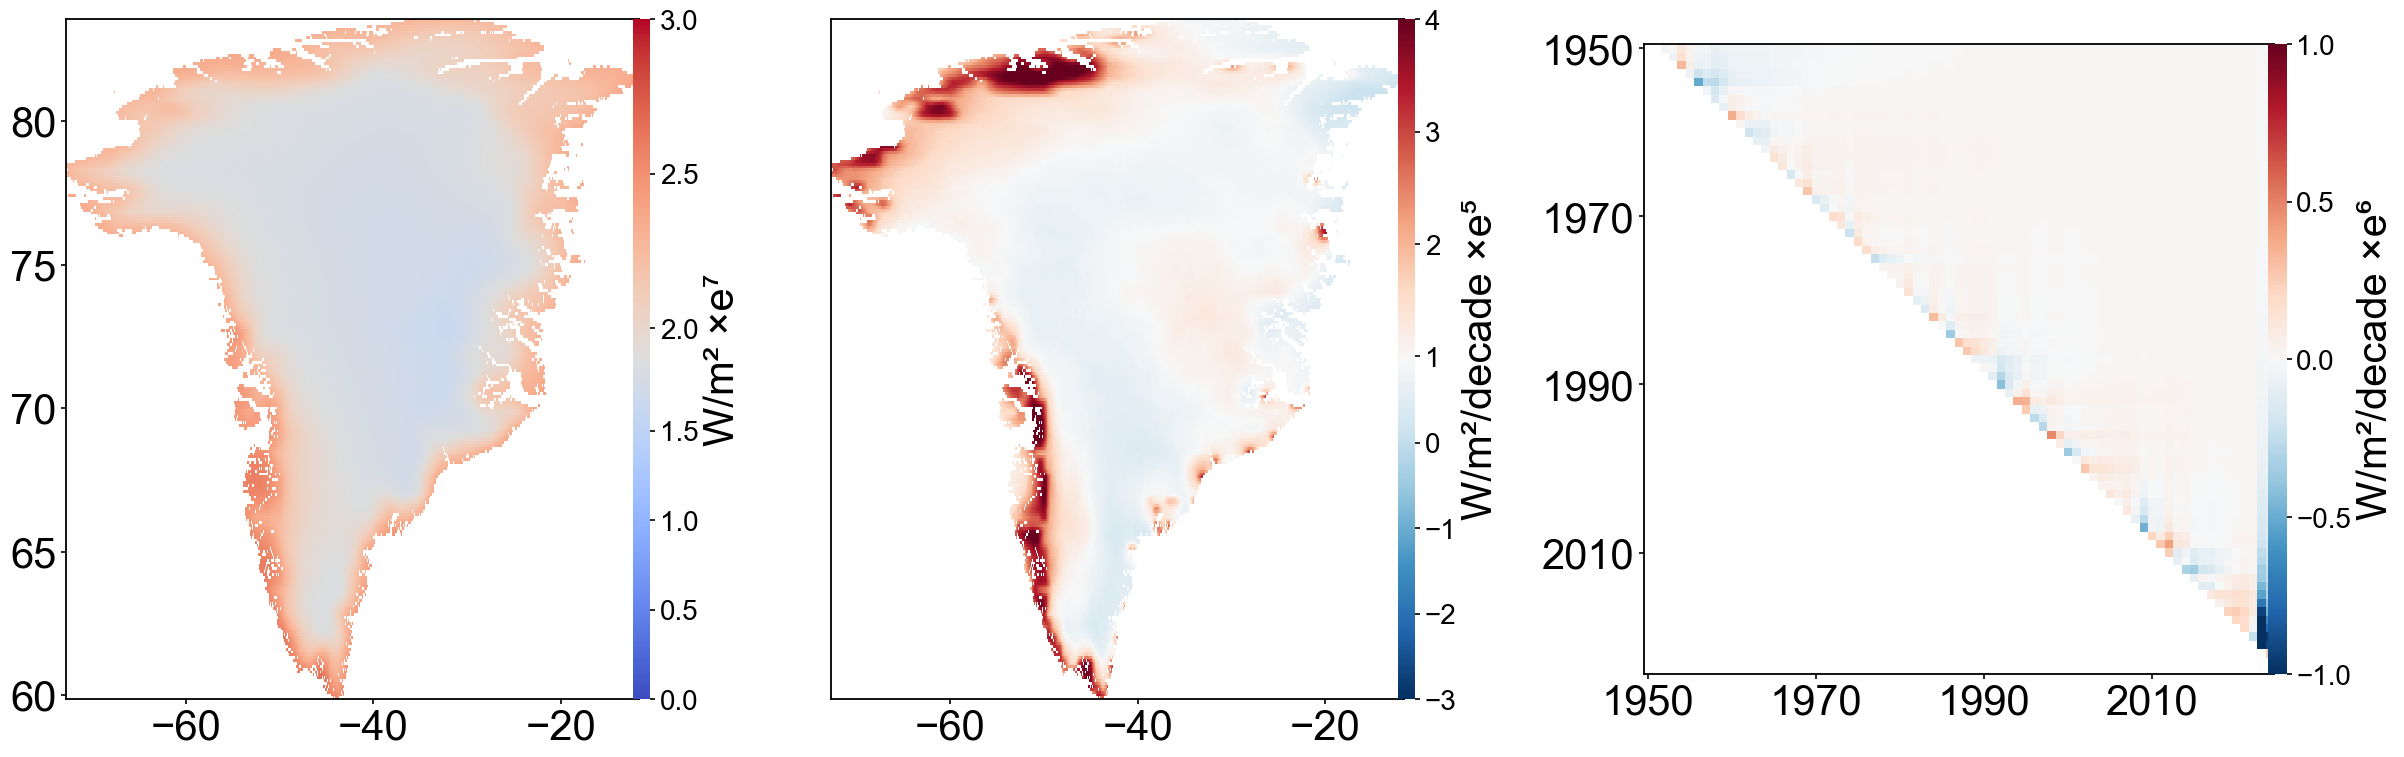

In [ ]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 =====
meantrend_csv = r"C:\greenland\1995bu\fig4\Greenland_strd_MeanTrend.csv"
sliding_csv   = r"C:\greenland\1995bu\fig4\Greenland_strd_SlidingTrend.csv"

# ===== 参数区 =====
FONT_SIZE      = 30   # ✅ 改大字体
CBAR_WIDTH     = "3%"
CBAR_PAD       = 0.02
WSPACE_12      = 0.08
WSPACE_23      = 0.1
TOP_ALIGN      = 0.95

# ==== 单位与范围 ====
UNIT_MEAN   = "W/m² ×e⁷"
UNIT_TREND  = "W/m²  ×e⁵"
UNIT_SLIDE  = "W/m²  ×e⁶"   # ✅ 改成 e6

MEAN_VMIN, MEAN_VMAX = 0, 3
TREND_VMIN, TREND_VMAX = -3, 4

# ===== 读数据 =====
df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])

# ===== pivot重构格网 =====
mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)

# ===== 单位调整（按 e5） =====
trend_grid = trend_grid / 1e5

lats, lons = mean_grid.index.values, mean_grid.columns.values

# ===== 自动中间值 (保留白色分界) =====
MEAN_VCENTER  = np.nanmedian(mean_grid.values / 1e7)
TREND_VCENTER = np.nanmedian(trend_grid.values)

# ===== 滑动趋势 =====
slide = pd.read_csv(sliding_csv, index_col=0)
years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
vals = slide.to_numpy(dtype=float) / 1e6   # ✅ 改成 e6
mask = np.tril(np.ones_like(vals, dtype=bool), -1)
vals_masked = np.ma.array(vals, mask=mask)

# ===== 绘图风格 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

# ===== 图形布局 =====
fig = plt.figure(figsize=(24, 8))
left_margin, right_margin = 0.05, 0.97
total_width = right_margin - left_margin
total_gap = WSPACE_12 + WSPACE_23

w1_ratio, w2_ratio, w3_ratio = 1.0, 1.0, 1.1
total_ratio = w1_ratio + w2_ratio + w3_ratio
available_width = total_width - total_gap
w1 = available_width * (w1_ratio / total_ratio)
w2 = available_width * (w2_ratio / total_ratio)
w3 = available_width * (w3_ratio / total_ratio)
left1, left2, left3 = left_margin, left_margin + w1 + WSPACE_12, left_margin + w1 + WSPACE_12 + w2 + WSPACE_23

ax0 = fig.add_axes([left1, 0.1, w1, TOP_ALIGN - 0.1])
ax1 = fig.add_axes([left2, 0.1, w2, TOP_ALIGN - 0.1], sharey=ax0)
ax2 = fig.add_axes([left3, 0.1, w3, TOP_ALIGN - 0.1])

# === (1) 夏季均值 ===
norm_mean = TwoSlopeNorm(vmin=MEAN_VMIN, vcenter=MEAN_VCENTER, vmax=MEAN_VMAX)
im0 = ax0.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="coolwarm", norm=norm_mean, shading="auto")
cb0_ax = inset_axes(ax0, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax0.transAxes, borderpad=0)
cb0 = fig.colorbar(im0, cax=cb0_ax)
cb0.set_label(UNIT_MEAN, fontsize=FONT_SIZE)
cb0.outline.set_visible(False)
cb0.set_ticks([0, 0.5,1,1.5, 2,2.5, 3])  # 固定4个刻度

# === (2) 趋势图 ===
norm_trend = TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX)
im1 = ax1.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r", norm=norm_trend, shading="auto")
cb1_ax = inset_axes(ax1, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax1.transAxes, borderpad=0)
cb1 = fig.colorbar(im1, cax=cb1_ax)
cb1.set_label(UNIT_TREND, fontsize=FONT_SIZE)
cb1.outline.set_visible(False)
cb1.set_ticks([-3, -2, -1, 0, 1, 2, 3, 4])
ax1.tick_params(left=False, labelleft=False)

# === (3) 滑动趋势热力图 ===
vmax_slide = 1   # ✅ 改范围 ±1
norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
im2 = ax2.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r", norm=norm_slide, shading="auto")
ax2.invert_yaxis()
cb2_ax = inset_axes(ax2, width=CBAR_WIDTH, height="100%", loc='right',
                    bbox_to_anchor=(CBAR_PAD, 0, 1, 1), bbox_transform=ax2.transAxes, borderpad=0)
cb2 = fig.colorbar(im2, cax=cb2_ax)
cb2.set_label(UNIT_SLIDE, fontsize=FONT_SIZE)
cb2.outline.set_visible(False)
cb2.set_ticks(np.linspace(-1, 1, 5))  # 刻度 -1, -0.5, 0, 0.5, 1

# === 样式统一 ===
for ax in [ax0, ax1, ax2]:
    ax.tick_params(labelsize=FONT_SIZE)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")

ax2.set_xticks(np.arange(1950, 2030, 20))   # ✅ 改为每 20 年
ax2.set_yticks(np.arange(1950, 2030, 20))
ax2.set_aspect('equal')

plt.show()


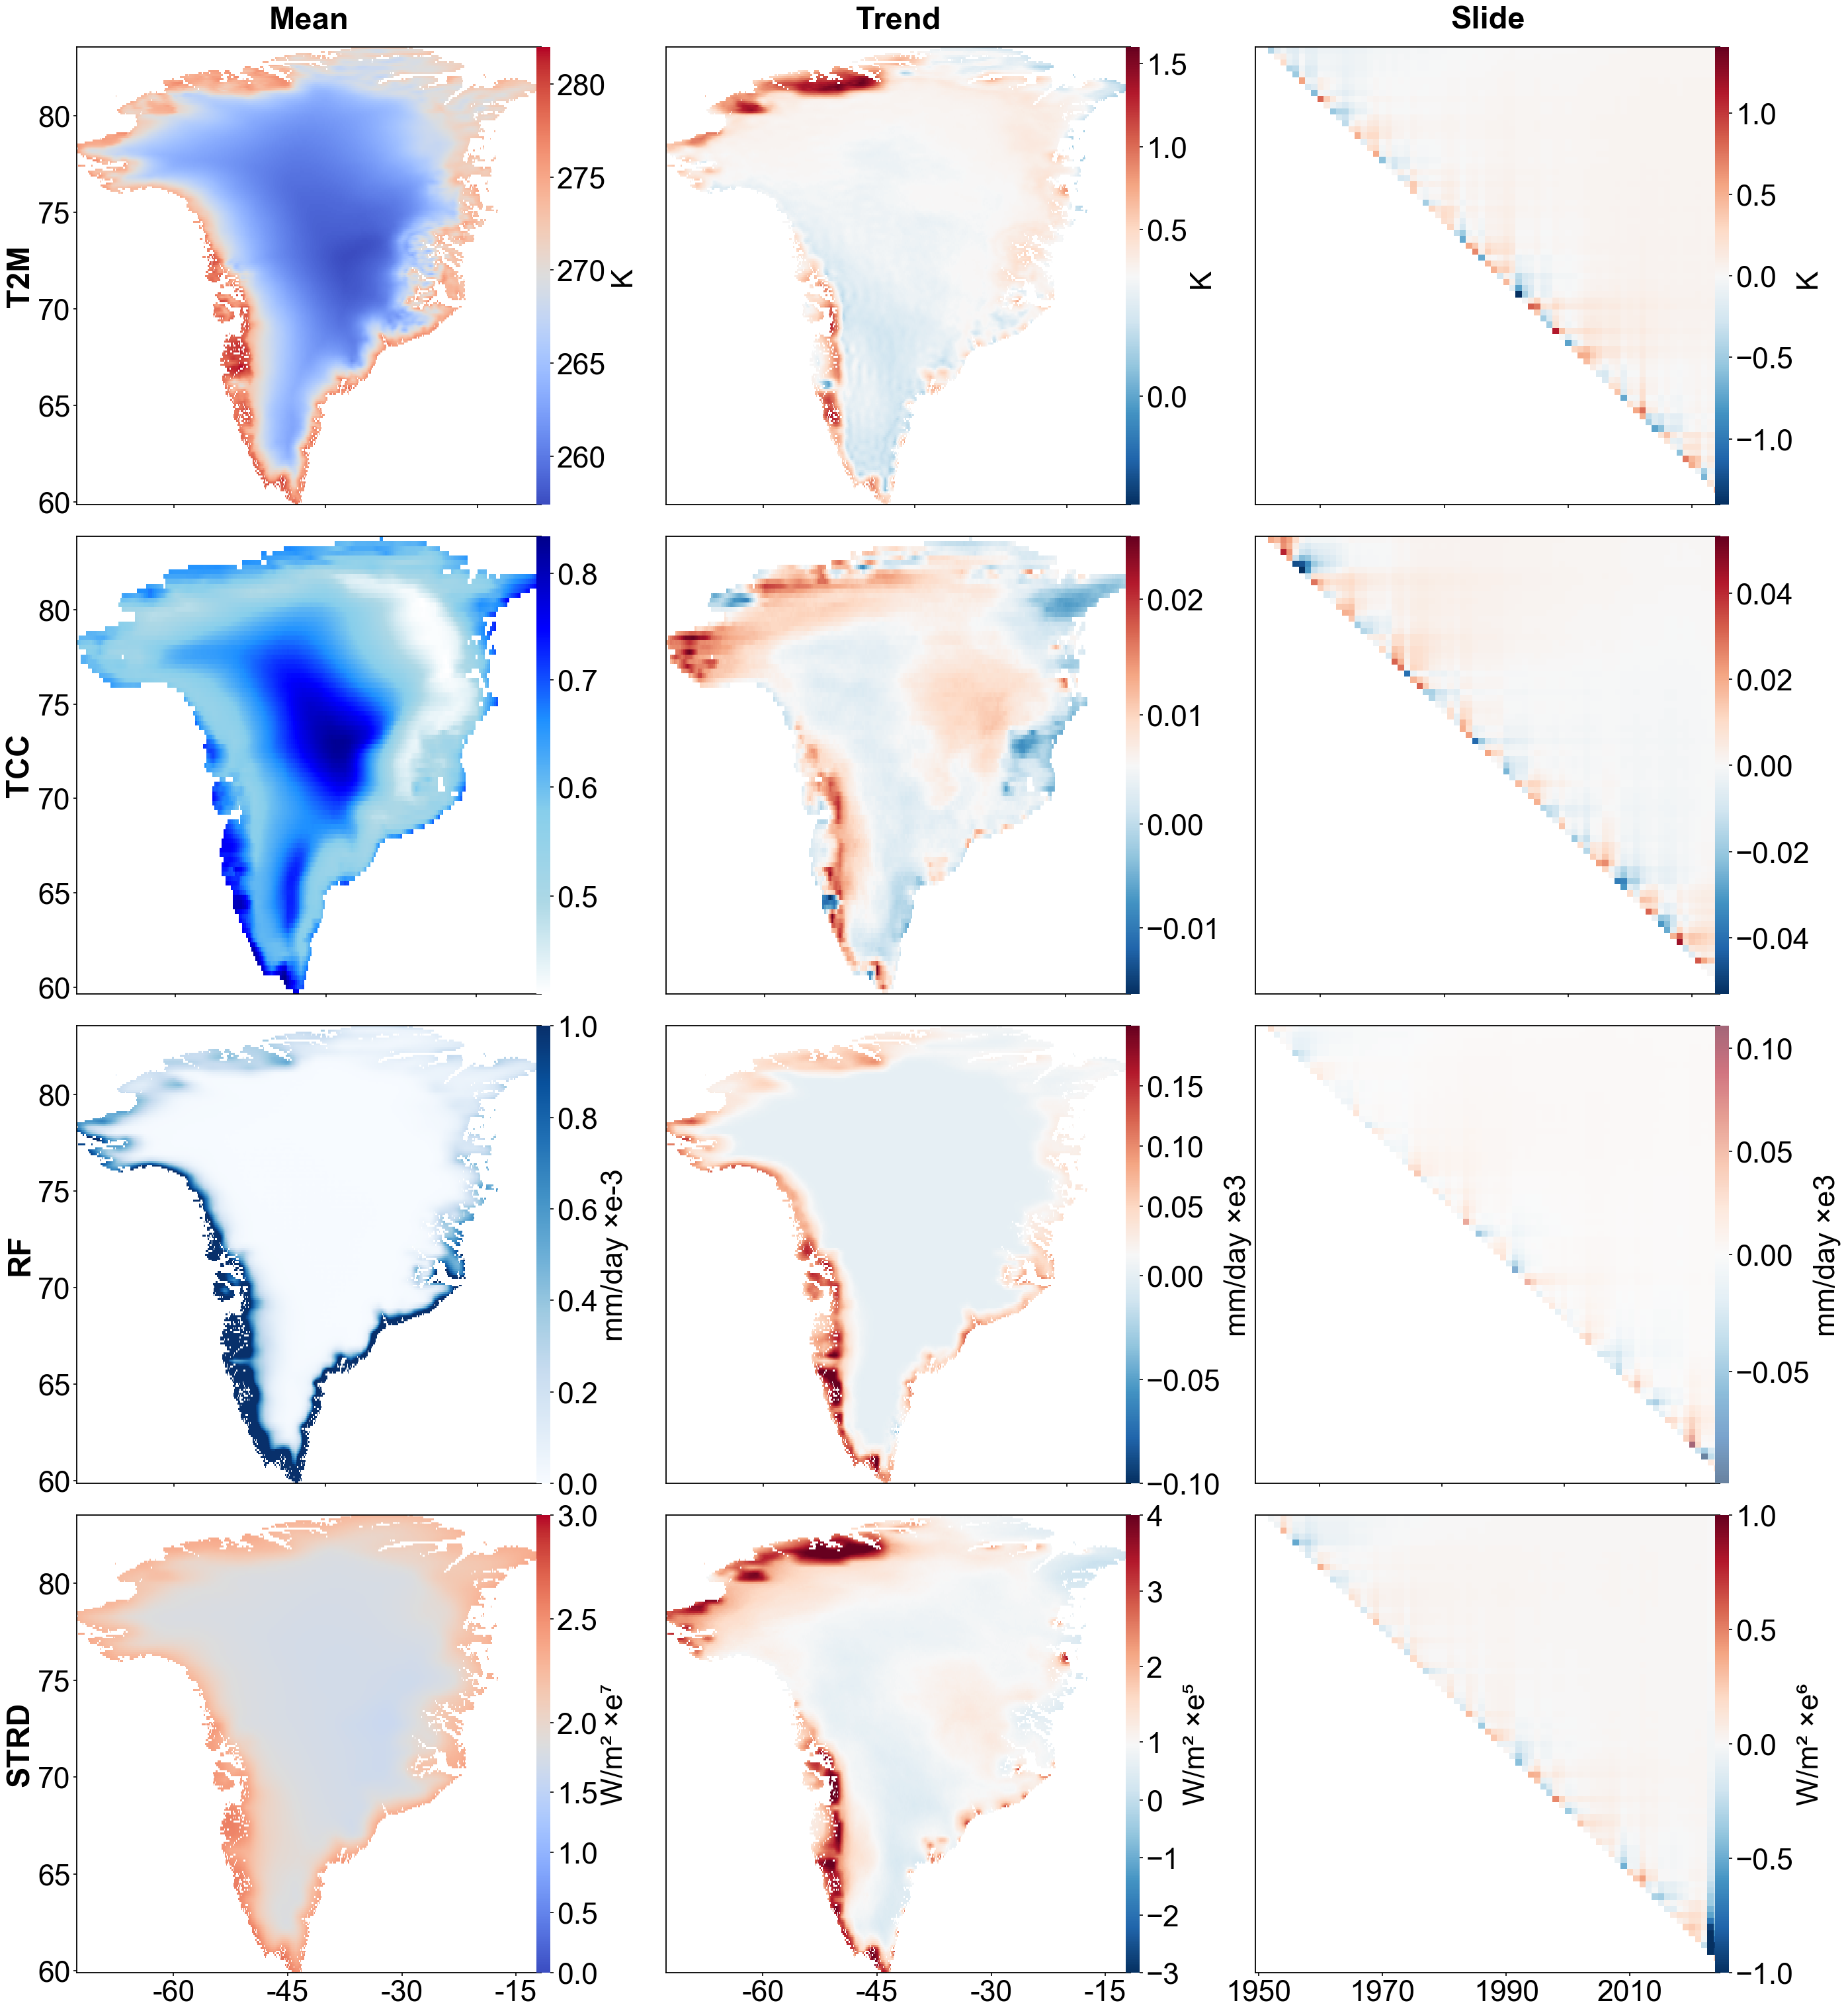

In [207]:
# -*- coding: utf-8 -*-
"""
Final 4×3 Greenland Climate Panel (t2m / tcc / rf / strd)
- STRD 行：Mean/Trend 显示经度刻度；Slide 显示年份刻度
- 字号统一：32
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

# ===== 参数区 =====
FONT_SIZE = 32
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0.015
WSPACE = 0.07
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig4_4x3panel.png"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

fig = plt.figure(figsize=(27, 32))
VARS = ["t2m", "tcc", "rf", "strd"]
COL_NAMES = ["Mean", "Trend", "Slide"]

n_rows, n_cols = len(VARS), len(COL_NAMES)
left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows

axes = []

# ========== 绘图循环 ==========
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)
        CBAR_WIDTH, CBAR_PAD = "3%", 0.02

        if var == "t2m":
            meantrend_csv = f"{DATA_DIR}\\Greenland_t2m_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_t2m_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)

            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            TREND_VMIN, TREND_VCENTER, TREND_VMAX = -0.2, 0.22, 1.6

            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="coolwarm", shading="auto")
                label = "K"
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX),
                                   shading="auto")
                label = "K "
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = "K "

        elif var == "tcc":
            meantrend_csv = f"{DATA_DIR}\\Greenland_tcc_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_tcc_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)

            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)

            colors_cloud = ['white','lightblue','skyblue','dodgerblue','blue','darkblue']
            cmap_cloud = LinearSegmentedColormap.from_list('cloud', colors_cloud)
            vcenter_mean = 0.62

            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap=cmap_cloud,
                                   norm=TwoSlopeNorm(vmin=np.nanmin(mean_grid), vcenter=vcenter_mean, vmax=np.nanmax(mean_grid)),
                                   shading="auto")
                label = ""
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=np.nanmedian(trend_grid), vmax=np.nanmax(trend_grid)),
                                   shading="auto")
                label = " "
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = " "

        elif var == "rf":
            meantrend_csv = f"{DATA_DIR}\\Greenland_rf_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_rf_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)

            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values

            mean_scaled = mean_grid.values * 1e3
            trend_scaled = trend_grid.values * 1e3
            vals = slide.to_numpy(dtype=float) * 1e3
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)

            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="Blues",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
                label = r"mm/day ×e-3"
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.1, vcenter=0.01, vmax=0.2),
                                   shading="auto")
                label = r"mm/day ×e3"
            else:
                cmap_slide = plt.cm.RdBu_r
                colors_slide = cmap_slide(np.linspace(0,1,256)); colors_slide[:,-1]=0.6
                cmap_slide_light = mcolors.ListedColormap(colors_slide)
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=cmap_slide_light,
                                   norm=TwoSlopeNorm(vmin=np.nanmin(vals_masked), vcenter=0, vmax=np.nanmax(vals_masked)),
                                   shading="auto")
                ax.invert_yaxis()
                label = r"mm/day ×e3"

        elif var == "strd":
            # === 采用“单独代码”的画法 + 经度刻度 ===
            meantrend_csv = f"{DATA_DIR}\\Greenland_strd_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_strd_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])

            # 强制数值化并排序，保证 pcolormesh 单调
            df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
            df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
            df = df.dropna(subset=["lat","lon"])

            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid  = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)

            trend_grid = trend_grid / 1e5
            lats = mean_grid.index.values.astype(float)
            lons = mean_grid.columns.values.astype(float)

            MEAN_VMIN, MEAN_VMAX = 0, 3
            TREND_VMIN, TREND_VMAX = -3, 4
            MEAN_VCENTER  = float(np.nanmedian(mean_grid.values / 1e7))
            TREND_VCENTER = float(np.nanmedian(trend_grid.values))
            eps = 1e-9
            MEAN_VCENTER = np.clip(MEAN_VCENTER, MEAN_VMIN+eps, MEAN_VMAX-eps)
            TREND_VCENTER = np.clip(TREND_VCENTER, TREND_VMIN+eps, TREND_VMAX-eps)

            slide = pd.read_csv(sliding_csv, index_col=0)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float) / 1e6
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)

            if col == "Mean":
                norm_mean = TwoSlopeNorm(vmin=MEAN_VMIN, vcenter=MEAN_VCENTER, vmax=MEAN_VMAX)
                im = ax.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="coolwarm",
                                   norm=norm_mean, shading="auto")
                ax.set_xlim(lons.min(), lons.max())
                ax.set_ylim(lats.min(), lats.max())
                # —— 给 STRD Mean 加经度刻度 —— #
                ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
                ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
                label = "W/m² ×e⁷"

            elif col == "Trend":
                norm_trend = TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX)
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=norm_trend, shading="auto")
                ax.set_xlim(lons.min(), lons.max())
                ax.set_ylim(lats.min(), lats.max())
                # —— 给 STRD Trend 加经度刻度 —— #
                ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
                ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
                label = "W/m² ×e⁵"

            else:
                vmax_slide = 1.0
                norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=norm_slide, shading="auto")
                ax.invert_yaxis()
                label = "W/m² ×e⁶"

        # ===== colorbar 统一 =====
        cb_ax = inset_axes(ax, width=CBAR_WIDTH, height="100%", loc='right',
                           bbox_to_anchor=(CBAR_PAD,0,1,1), bbox_transform=ax.transAxes, borderpad=0)
        cb = fig.colorbar(im, cax=cb_ax)
        cb.set_label(label, fontsize=FONT_SIZE)
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=FONT_SIZE)

        # ===== 样式与标题 =====
        ax.tick_params(labelsize=FONT_SIZE)

        # 仅隐藏非最后一行的 x 刻度（底行全部显示）
        if i < n_rows - 1:
            ax.set_xticklabels([])

        # 第2、3列隐藏 y 刻度
        if j > 0:
            ax.tick_params(left=False, labelleft=False)

        # 顶部列标题
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=20)

        # 左侧行标题
        if j == 0:
            ax.text(-0.09, 0.5, var.upper(), transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)

# ===== 仅为 STRD/Slide 设置年份刻度 =====
axes[-1].set_xticks(np.arange(1950, 2030, 20))
axes[-1].tick_params(labelsize=FONT_SIZE)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()


C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2541842929.py:269: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


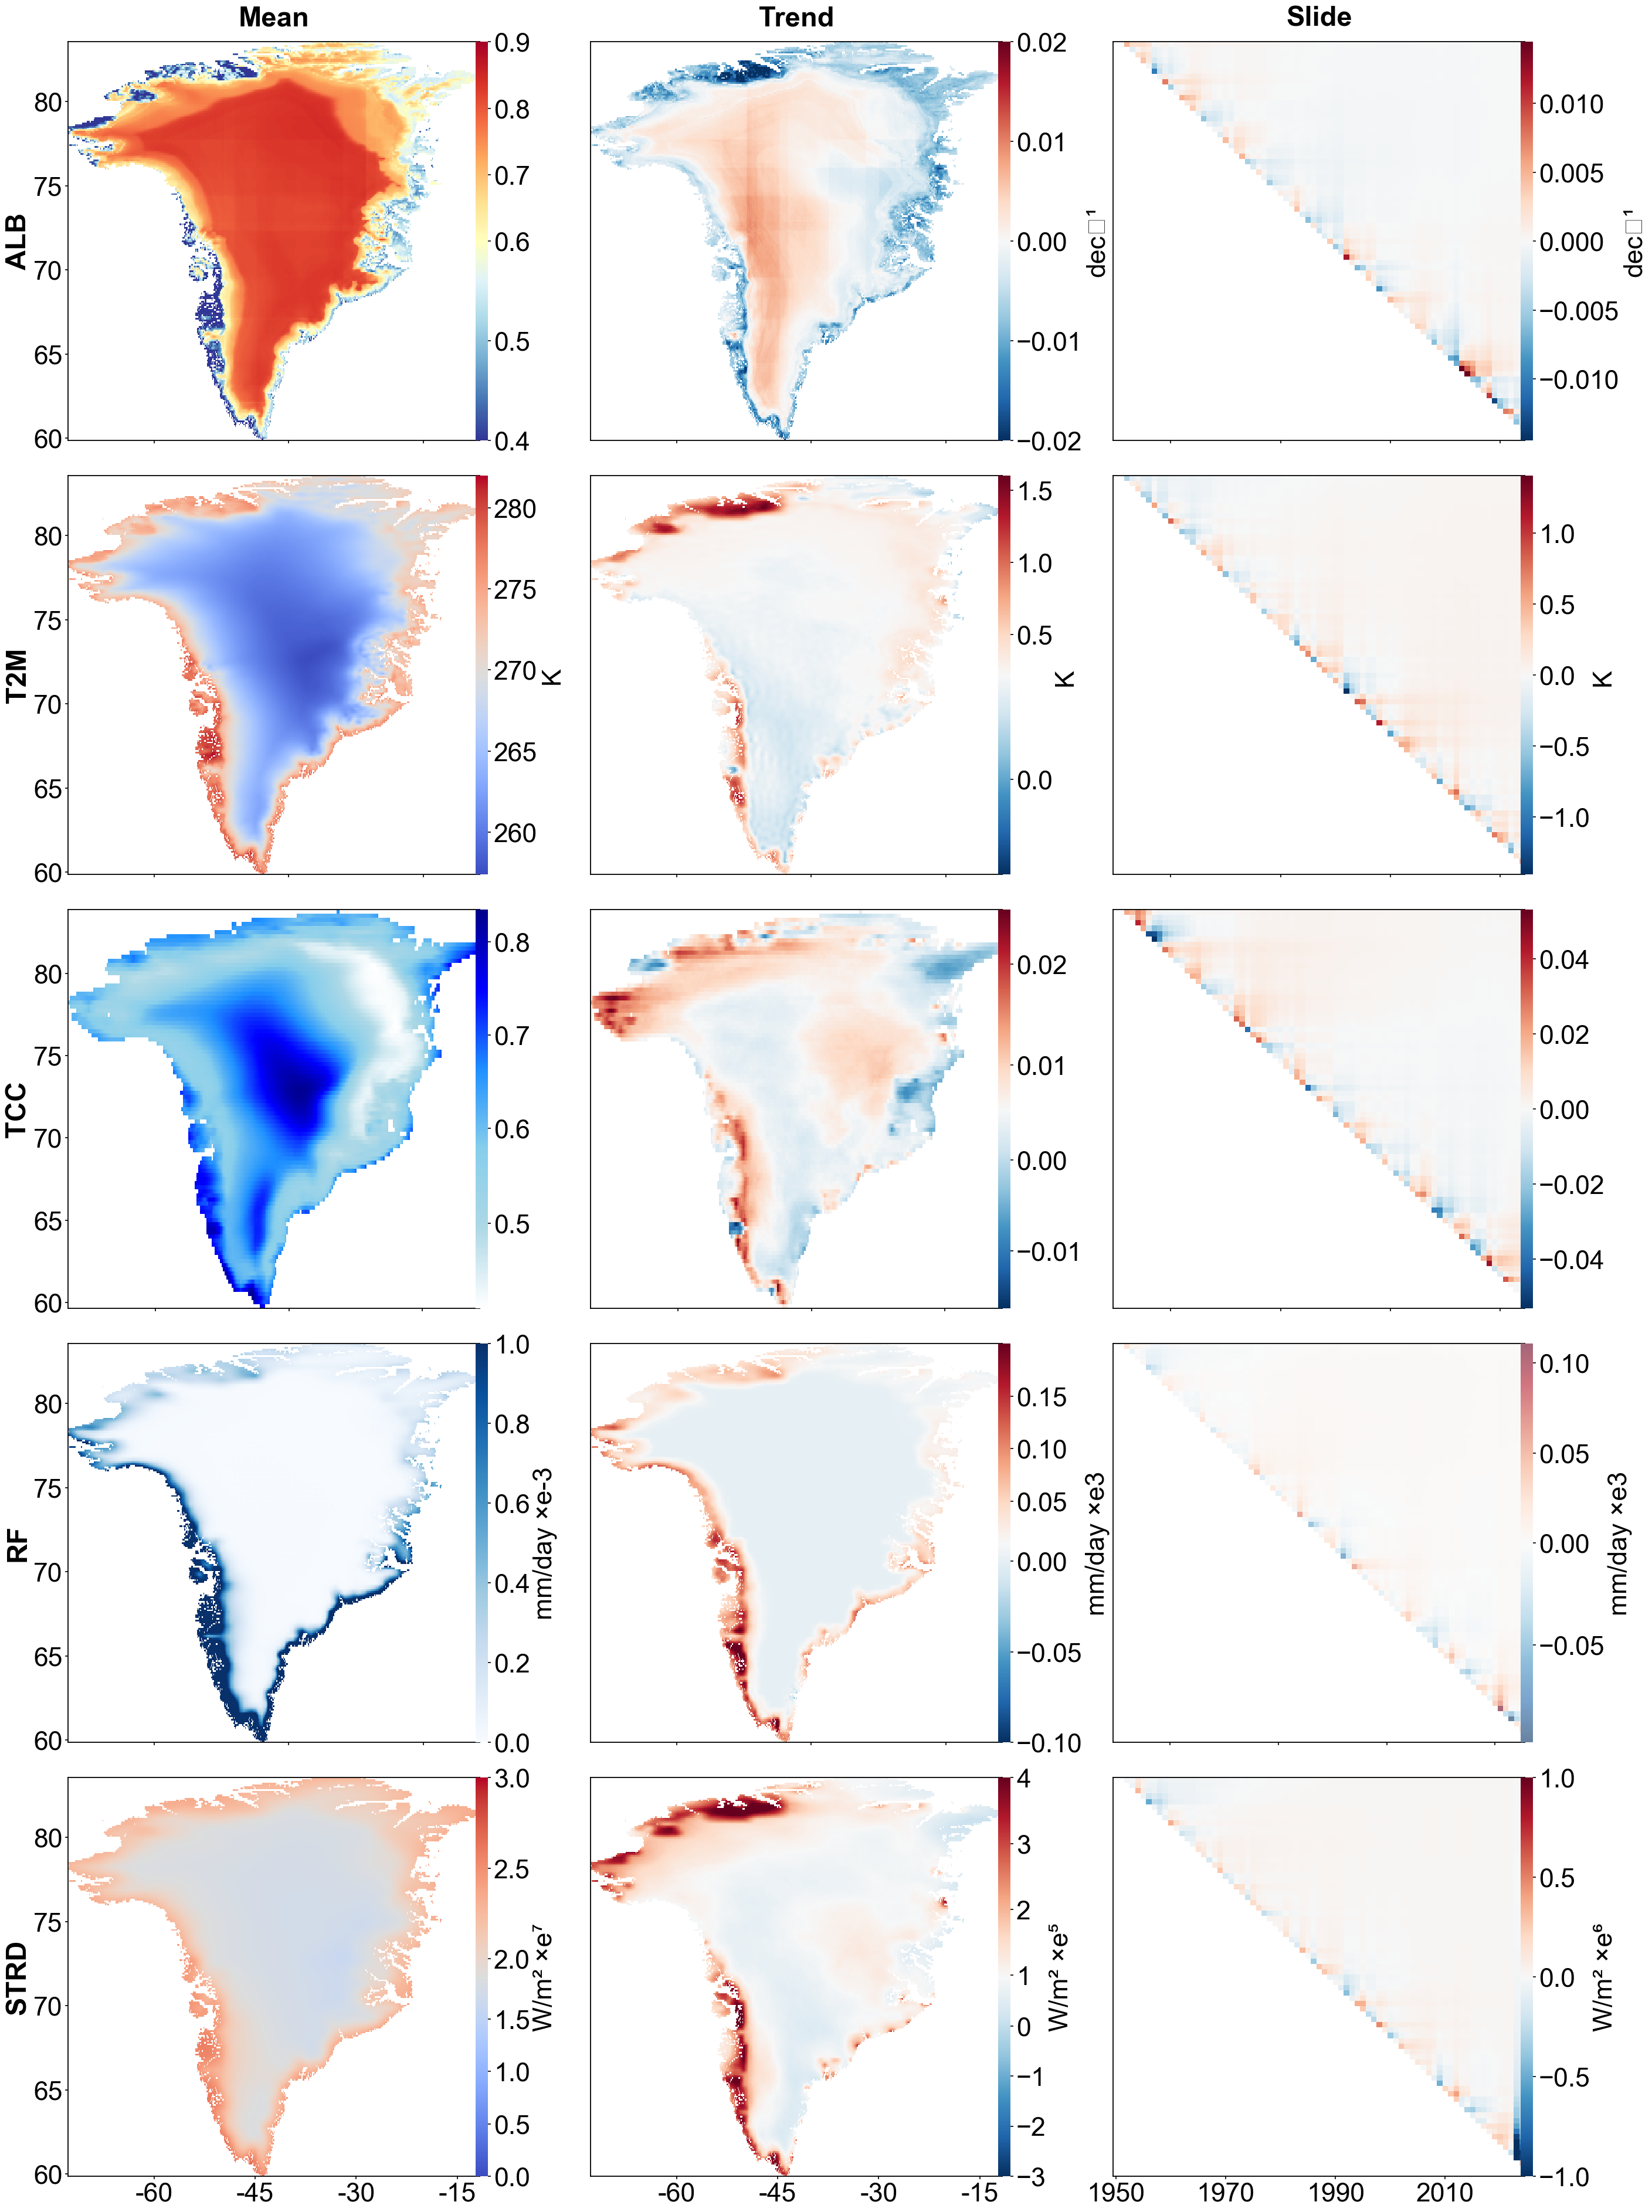

In [ ]:
# -*- coding: utf-8 -*-
"""
Add ALB basin letters and contour overlay
"""
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 文件路径 =====
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig4_5x3panel.png"
BASIN_SHP = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_SHP = r"C:\greenland\Greenland_shp\等间距等值线.shp"

# ===== 样式参数 =====
FONT_SIZE = 32
TITLE_SIZE = FONT_SIZE + 2
plt.rcParams.update({"font.family": "Arial", "font.size": FONT_SIZE, "axes.linewidth": 1.3})
fig = plt.figure(figsize=(27, 40))

VARS = ["alb", "t2m", "tcc", "rf", "strd"]
COL_NAMES = ["Mean", "Trend", "Slide"]

# ======= 读取 shapefile =======
basin_shp = gpd.read_file(BASIN_SHP)
contour_shp = gpd.read_file(CONTOUR_SHP)

# ======= 绘图循环（仅展示ALB部分修改） =======
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        if var != "alb":  # 这里略去其他变量（保持原逻辑）
            continue

        ax = plt.subplot2grid((5, 3), (i, j))
        meantrend_csv = f"{DATA_DIR}\\Greenland_alb_MeanTrend.csv"
        sliding_csv = f"{DATA_DIR}\\Greenland_alb_SlidingTrend.csv"
        df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])

        mean_grid = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
        trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
        lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)

        # ======= 绘图逻辑 =======
        if col == "Mean":
            im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="RdYlBu_r",
                               vmin=0, vmax=1, shading="auto")
            label = " "
            # === 添加流域边界 ===
            basin_shp.boundary.plot(ax=ax, color="k", linewidth=1.2)
            # === 添加方位字母 ===
            labels = {"N": (78, -45), "NW": (75, -50), "NE": (77, -35),
                      "W": (72, -48), "E": (70, -34),
                      "SW": (66, -47), "SE": (65, -40), "S": (62, -44)}
            for txt, (lat, lon) in labels.items():
                ax.text(lon, lat, txt, fontsize=FONT_SIZE, color="gray",
                        fontweight="bold", ha="center", va="center", alpha=0.8)

        elif col == "Trend":
            im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                               norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02),
                               shading="auto")
            label = "dec⁻¹"
            # === 添加等高线 ===
            contour_shp.boundary.plot(ax=ax, color="k", linewidth=0.8, alpha=0.6)

        else:
            slide = pd.read_csv(sliding_csv, index_col=0)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            vmax_slide = np.nanmax(np.abs(vals_masked))
            im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                               norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                               shading="auto")
            ax.invert_yaxis()
            label = "dec⁻¹"

        # === colorbar ===
        cb_ax = inset_axes(ax, width="3%", height="100%", loc='right',
                           bbox_to_anchor=(0.02, 0, 1, 1), bbox_transform=ax.transAxes, borderpad=0)
        cb = fig.colorbar(im, cax=cb_ax)
        cb.set_label(label, fontsize=FONT_SIZE)
        cb.ax.tick_params(labelsize=FONT_SIZE)
        cb.outline.set_visible(False)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()


目标统一坐标系 (CRS): EPSG:3413

3. 流域冰盖 (共找到 9 个文件)。开始绘制和标注...
   - 绘制 East.shp，标注为 E
   - 绘制 EastNorth.shp，标注为 NE
   - 绘制 EastSouth.shp，标注为 SE
   - 绘制 Melt.shp，标注为 Melt


C:\Users\11823\AppData\Local\Temp\ipykernel_52312\22366070.py:62: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('tab10')


   - 绘制 North.shp，标注为 N
   - 绘制 South.shp，标注为 S
   - 绘制 West.shp，标注为 W
   - 绘制 WestNorth.shp，标注为 NW
   - 绘制 WestSouth.shp，标注为 SW


C:\Users\11823\AppData\Local\Temp\ipykernel_52312\22366070.py:128: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  other_handles, other_labels = ax.get_legend_handles_labels()
C:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22352 (\N{CJK UNIFIED IDEOGRAPH-5750}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 31859 (\N{CJK UNIFIED IDEOGRAPH-7C73}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26684 (\

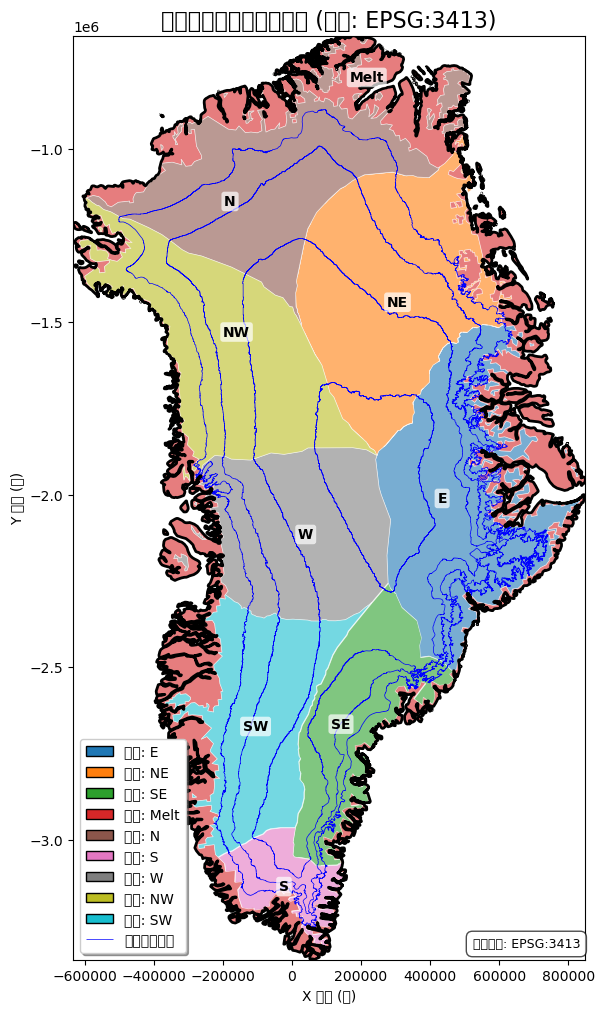

In [6]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import get_cmap
import os

# 定义文件路径
contour_path = r"C:\greenland\Greenland_shp\等间距等值线.shp"
boundary_path = r"C:\greenland\Greenland_shp\Gboundry.shp"
basin_dir = r"C:\greenland\Greenland_shp\流域冰盖"

# 目标投影坐标系：WGS 84 / NSIDC Sea Ice Polar Stereographic North
TARGET_CRS = "EPSG:3413" 

print(f"目标统一坐标系 (CRS): {TARGET_CRS}\n")

# ======================================================================
# !!! 精确缩写映射表 (已根据您的指令设置) !!!
# 键 (Key) 是 Shapefile 文件名的小写形式 (不含 .shp)
# 值 (Value) 是您希望在图上标注的缩写 (遵循南北在前规则)
# ======================================================================
BASIN_ABBR_MAP = {
    "eastnorth": "NE",
    "westnorth": "NW",
    "eastsouth": "SE",
    "westsouth": "SW",
    
    "east": "E",
    "north": "N",
    "south": "S",
    "west": "W",
    "melt": "Melt" # 保持不变
}
# ======================================================================

def get_abbreviation(filename):
    """通过精确查找映射表获取缩写"""
    # 移除文件扩展名，转换为小写，并去除所有非字母数字字符（如空格、下划线等），确保精确匹配
    name_base = "".join(filter(str.isalnum, os.path.splitext(filename)[0].lower()))
    
    # 使用 .get() 方法，如果找不到精确匹配，则返回文件名大写作为默认值
    return BASIN_ABBR_MAP.get(name_base, name_base.upper())


try:
    # --- 1. 读取和重投影 等值线 和 完整轮廓 ---
    contours = gpd.read_file(contour_path).to_crs(TARGET_CRS)
    boundary = gpd.read_file(boundary_path).to_crs(TARGET_CRS)

    # --- 2. 准备流域文件列表 ---
    # 使用 sorted() 确保绘制和颜色分配的一致性
    basin_files = sorted([f for f in os.listdir(basin_dir) if f.endswith('.shp')])
    if not basin_files:
        raise FileNotFoundError(f"在 {basin_dir} 文件夹中未找到任何 .shp 文件。")
        
    print(f"3. 流域冰盖 (共找到 {len(basin_files)} 个文件)。开始绘制和标注...")
    
    # --- 3. 绘图设置 ---
    fig, ax = plt.subplots(1, 1, figsize=(12, 12))
    
    # 使用颜色映射
    cmap = get_cmap('tab10') 
    norm = Normalize(vmin=0, vmax=len(basin_files) - 1)
    
    basin_patches = []
    drawn_abbrs = set() 

    # --- 4. 循环绘制流域和标注 ---
    for i, filename in enumerate(basin_files):
        file_path = os.path.join(basin_dir, filename)
        
        try:
            basin_gdf = gpd.read_file(file_path).to_crs(TARGET_CRS)
        except Exception as e:
            print(f"**错误：无法读取或重投影文件 {filename}：{e}**")
            continue
            
        # 获取缩写
        abbr = get_abbreviation(filename)
        print(f"   - 绘制 {filename}，标注为 {abbr}")
        
        # 绘制流域多边形
        color = cmap(norm(i % 10)) 
        basin_gdf.plot(
            ax=ax, 
            color=color, 
            edgecolor='white', # 明显的白色分界线
            linewidth=0.5, 
            alpha=0.6, 
            zorder=1
        )
        
        # 计算并添加标注
        if not basin_gdf.empty:
            # 使用 representative_point 确保标签在多边形内部
            center_point = basin_gdf.geometry.iloc[0].representative_point()
            
            ax.text(
                center_point.x, 
                center_point.y, 
                abbr, 
                fontsize=10, 
                fontweight='bold', 
                ha='center', 
                va='center', 
                color='black',
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, edgecolor='none'),
                zorder=4
            )

        # 收集图例信息
        if abbr not in drawn_abbrs:
             from matplotlib.patches import Patch
             basin_patches.append(Patch(facecolor=color, edgecolor='black', label=f'流域: {abbr}'))
             drawn_abbrs.add(abbr)


    # --- 5. 绘制轮廓和等值线 ---
    boundary.plot(ax=ax, edgecolor='black', facecolor='none', linewidth=2, zorder=3, label='完整轮廓')
    contours.plot(ax=ax, color='blue', linewidth=0.5, zorder=2, label='等间距等值线')

    # --- 6. 设置图表属性 ---
    ax.set_title(f"格陵兰岛冰盖要素叠加图 (投影: {TARGET_CRS})", fontsize=16)
    ax.set_xlabel("X 坐标 (米)")
    ax.set_ylabel("Y 坐标 (米)")
    
    # 显示图例
    other_handles, other_labels = ax.get_legend_handles_labels()
    final_handles = basin_patches + [h for h, l in zip(other_handles, other_labels) if not l.startswith('流域: ')]
    final_labels = [h.get_label() for h in final_handles]
    
    ax.legend(final_handles, final_labels, loc='lower left', fancybox=True, shadow=True)
    
    # 调整显示比例
    ax.set_aspect('equal')
    ax.autoscale(enable=True, axis='both', tight=True)

    plt.text(0.99, 0.01, f"统一投影: {TARGET_CRS}", transform=ax.transAxes, fontsize=9, ha='right', va='bottom', bbox=dict(boxstyle="round,pad=0.5", fc="white", alpha=0.7))
    
    plt.show()

except FileNotFoundError as e:
    print(f"\n--- 错误：文件未找到 ---")
    print(e)
except Exception as e:
    print(f"\n--- 绘图过程中发生意外错误 ---")
    print(e)
    print("\n请检查文件路径和 geopandas、matplotlib 等库的安装情况。")